In [98]:
# cell 1: Install required libraries, load the dataset, and display the first five rows.

%pip install seaborn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

candidate_files = [
    Path("../data/raw/Customer_Cancellations_Training (1).csv"),
    Path("data/raw/Customer_Cancellations_Training (1).csv"),
    Path("Customer_Cancellations_Training (1).csv"),
    Path("../Customer_Cancellations_Training (1).csv"),
]

dataset_path = next((path for path in candidate_files if path.exists()), None)

if dataset_path is None:
    raise FileNotFoundError(
        "Upload Customer_Cancellations_Training (1).csv "
        "to the same folder as this notebook."
    )

df = pd.read_csv(dataset_path)

print("Dataset file:", dataset_path)
print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())

Dataset file: Customer_Cancellations_Training (1).csv
Dataset loaded successfully.
Dataset shape: (3160, 18)
Column names: ['AccountID', 'Territory', 'Country', 'DeviceType', 'Promotion', 'HasRenewed', 'PlanType', 'BaseFee', 'AdditionalFeatureSpend', 'NumberOfPenalties', 'CurrentPeriodUsage', 'PriorPeriodUsage', 'ServiceRating', 'ServiceTickets', 'StartMonth', 'StartWeek', 'CustomerTenure', 'Churned']


,AccountID,Territory,Country,DeviceType,Promotion,HasRenewed,PlanType,BaseFee,AdditionalFeatureSpend,NumberOfPenalties,CurrentPeriodUsage,PriorPeriodUsage,ServiceRating,ServiceTickets,StartMonth,StartWeek,CustomerTenure,Churned
0,aa16887,RI,USA,-,no,yes,Purple Plan,33.52,18,4,210.1,211.7,8.3,4,Jan,W02,99,no
1,aa33376,SC,USA,-,no,no,Red Plan,28.61,19,1,241.0,221.2,12.5,1,Dec,W51,112,no
2,aa57561,NJ,USA,-,yes,no,Purple Plan,24.89,8,2,220.0,89.7,15.6,4,Jun,W24,106,no
3,ab45280,OH,USA,-,yes,no,Purple Plan,27.15,14,3,244.1,168.8,9.6,9,Aug,W32,104,no
4,ab64231,NC,USA,iPhone,no,no,Green Plan,31.84,23,1,206.4,270.8,10.1,5,Feb,W08,85,no


In [126]:
# cell 2: Inspect dataset structure and generate descriptive statistics.

print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe())

Dataset shape: (3160, 18)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 3160 entries, 0 to 3159
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   AccountID               3160 non-null   str    
 1   Territory               3160 non-null   str    
 2   Country                 3160 non-null   str    
 3   DeviceType              3160 non-null   str    
 4   Promotion               3160 non-null   str    
 5   HasRenewed              3160 non-null   str    
 6   PlanType                3160 non-null   str    
 7   BaseFee                 3160 non-null   float64
 8   AdditionalFeatureSpend  3160 non-null   int64  
 9   NumberOfPenalties       3160 non-null   int64  
 10  CurrentPeriodUsage      3160 non-null   float64
 11  PriorPeriodUsage        3160 non-null   float64
 12  ServiceRating           3160 non-null   float64
 13  ServiceTickets          3160 non-null   int64  
 14  Sta

,BaseFee,AdditionalFeatureSpend,NumberOfPenalties,CurrentPeriodUsage,PriorPeriodUsage,ServiceRating,ServiceTickets,CustomerTenure
count,3160.000000,3160.000000,3160.000000,3160.000000,3160.000000,3160.000000,3160.000000,3160.000000
mean,30.554228,17.089873,1.563291,200.858418,200.985348,10.238006,4.462975,102.132595
std,9.245178,4.326222,1.318452,50.698090,50.736773,2.771476,2.444164,20.284144
min,0.440000,0.000000,0.000000,23.200000,0.000000,0.000000,0.000000,31.000000
25%,24.452500,14.000000,1.000000,167.075000,166.775000,8.500000,3.000000,89.000000
50%,30.480000,17.000000,1.000000,201.400000,201.100000,10.300000,4.000000,102.000000
75%,36.720000,20.000000,2.000000,235.325000,235.500000,12.100000,6.000000,116.000000
max,59.640000,31.000000,9.000000,395.000000,363.700000,20.000000,19.000000,167.000000


In [100]:
# cell 3: Check missing values, duplicate records, account IDs, and target distribution.

print("Missing values per column:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Unique AccountIDs:", df["AccountID"].nunique())
print("Unique Churned values:", df["Churned"].unique())

print("\nChurned class counts:")
display(df["Churned"].value_counts())

print("\nChurned class percentages:")
display((df["Churned"].value_counts(normalize=True) * 100).round(2))

Missing values per column:


AccountID                 0
Territory                 0
Country                   0
DeviceType                0
Promotion                 0
HasRenewed                0
PlanType                  0
BaseFee                   0
AdditionalFeatureSpend    0
NumberOfPenalties         0
CurrentPeriodUsage        0
PriorPeriodUsage          0
ServiceRating             0
ServiceTickets            0
StartMonth                0
StartWeek                 0
CustomerTenure            0
Churned                   0
dtype: int64


Duplicate rows: 0
Unique AccountIDs: 3160
Unique Churned values: <StringArray>
['no', 'yes']
Length: 2, dtype: str

Churned class counts:


Churned
no     2704
yes     456
Name: count, dtype: int64


Churned class percentages:


Churned
no     85.57
yes    14.43
Name: proportion, dtype: float64

In [101]:
# cell 4: Inspect unique values and missing values.

categorical_columns = df.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Categorical columns:", categorical_columns)

for column in categorical_columns:
    print(f"\n{column}")
    print("Unique values:", df[column].nunique())
    print(df[column].value_counts(dropna=False).head(15))

Categorical columns: ['AccountID', 'Territory', 'Country', 'DeviceType', 'Promotion', 'HasRenewed', 'PlanType', 'StartMonth', 'StartWeek', 'Churned']

AccountID
Unique values: 3160
AccountID
aa16887    1
aa33376    1
aa57561    1
ab45280    1
ab64231    1
ab77185    1
ab91714    1
ac12327    1
ac30783    1
ac64485    1
ac85629    1
ac86031    1
ac89116    1
ac93892    1
ad26775    1
Name: count, dtype: int64

Territory
Unique values: 51
Territory
WV    98
MN    82
AL    78
NY    77
VA    77
WY    74
OH    72
OR    72
WI    71
TX    71
VT    70
MI    69
MT    68
UT    68
CT    68
Name: count, dtype: int64

Country
Unique values: 1
Country
USA    3160
Name: count, dtype: int64

DeviceType
Unique values: 3
DeviceType
-         2160
iPhone     500
Galaxy     500
Name: count, dtype: int64

Promotion
Unique values: 2
Promotion
no     2288
yes     872
Name: count, dtype: int64

HasRenewed
Unique values: 2
HasRenewed
no     2858
yes     302
Name: count, dtype: int64

PlanType
Unique values: 4


In [102]:

# cell 5: Identify constant columns and unique identifiers for feature preparation.

constant_columns = [
    column for column in df.columns
    if df[column].nunique(dropna=False) <= 1
]

print("Constant columns:", constant_columns)

print("\nUnique values in AccountID:", df["AccountID"].nunique())
print("Total rows:", len(df))

if "Country" in df.columns:
    print("Unique values in Country:", df["Country"].nunique())


Constant columns: ['Country']

Unique values in AccountID: 3160
Total rows: 3160
Unique values in Country: 1


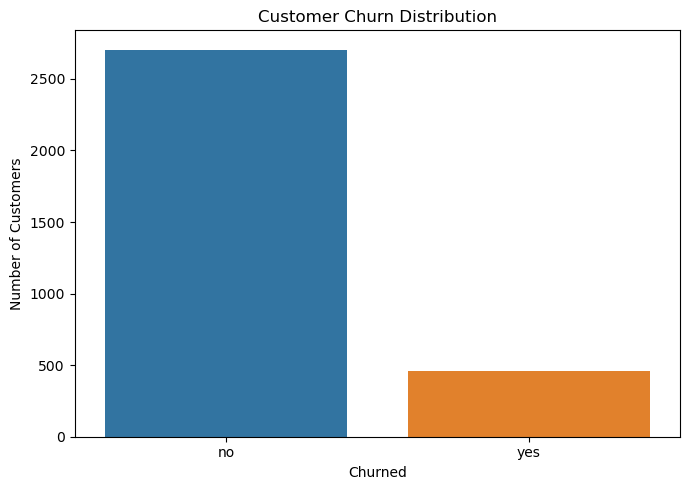


Churn counts:
Churned
no     2704
yes     456
Name: count, dtype: int64

Churn percentages:
Churned
no     85.57
yes    14.43
Name: proportion, dtype: float64


In [103]:

# cell 6: Visualize the distribution of customers who churned and stayed.

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churned", hue="Churned", legend=False)

plt.title("Customer Churn Distribution")
plt.xlabel("Churned")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("\nChurn counts:")
print(df["Churned"].value_counts())

print("\nChurn percentages:")
print((df["Churned"].value_counts(normalize=True) * 100).round(2))


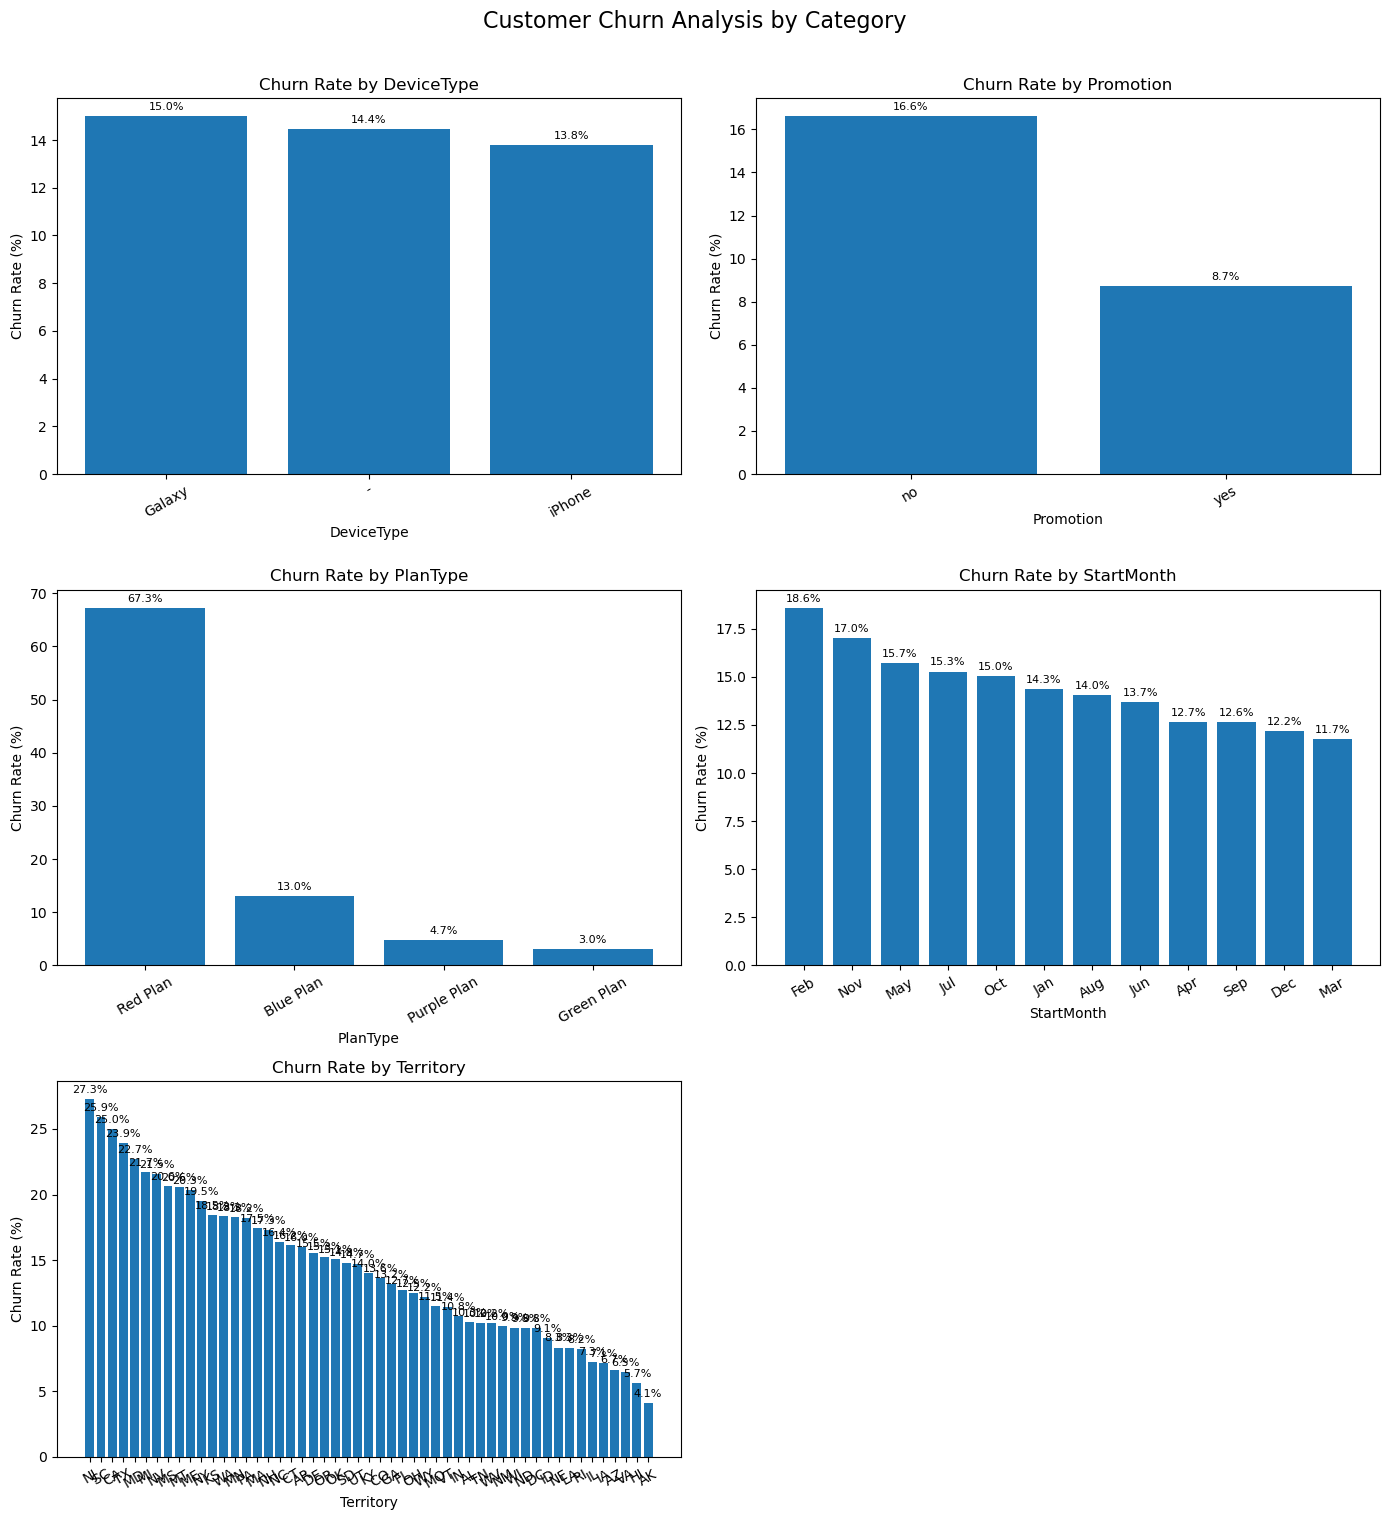

In [104]:
# cell 7: Compare churn percentages across categorical features using clean bar charts.

categorical_features = [
    "DeviceType",
    "Promotion",
    "PlanType",
    "StartMonth",
    "Territory"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for ax, column in zip(axes, categorical_features):
    churn_rate = (
        df.groupby(column, dropna=False, observed=True)["Churned"]
        .apply(lambda values: (values == "yes").mean() * 100)
        .sort_values(ascending=False)
    )

    ax.bar(churn_rate.index.astype(str), churn_rate.values)
    ax.set_title(f"Churn Rate by {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Churn Rate (%)")
    ax.tick_params(axis="x", rotation=30)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=8)

axes[-1].axis("off")
plt.suptitle("Customer Churn Analysis by Category", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()


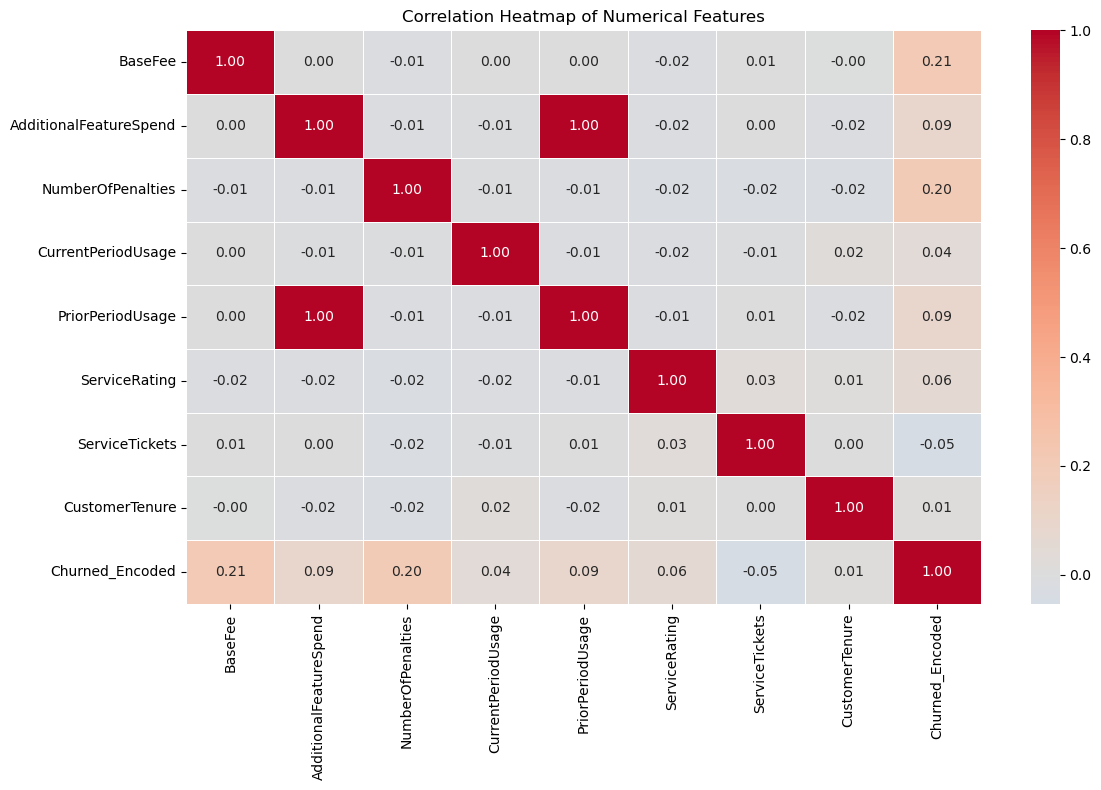

In [105]:

# cell 8: Visualize correlations among numerical features and the churn target.

numerical_df = df.select_dtypes(include=["number"]).copy()

if "Churned" in df.columns:
    numerical_df["Churned_Encoded"] = df["Churned"].map({"no": 0, "yes": 1})

correlation_matrix = numerical_df.drop(
    columns=["AccountID"], errors="ignore"
).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


In [106]:

# cell 9: Verify placeholder values and missing values in DeviceType.

print("DeviceType value counts:")
print(df["DeviceType"].value_counts(dropna=False))

placeholder_count = (df["DeviceType"] == "-").sum()
missing_count = df["DeviceType"].isna().sum()

print("\nPlaceholder '-' count:", placeholder_count)
print("Existing missing values:", missing_count)


DeviceType value counts:
DeviceType
-         2160
iPhone     500
Galaxy     500
Name: count, dtype: int64

Placeholder '-' count: 2160
Existing missing values: 0


In [107]:
# cell 10: Preserve DeviceType placeholder meaning instead of assuming '-' means Unknown.

# Preserve the literal '-' as its own explicit category without replacing it with other text.
# Handle genuine missing values separately.
# so information is not silently reinterpreted or discarded. Distinguish actual nulls.
df["DeviceType"] = df["DeviceType"].fillna("Missing (null)")

print("DeviceType values after cleaning:")
print(df["DeviceType"].value_counts(dropna=False))
print("Remaining missing DeviceType values:", df["DeviceType"].isna().sum())


DeviceType values after cleaning:
DeviceType
Not recorded (-)    2160
iPhone               500
Galaxy               500
Name: count, dtype: int64
Remaining missing DeviceType values: 0


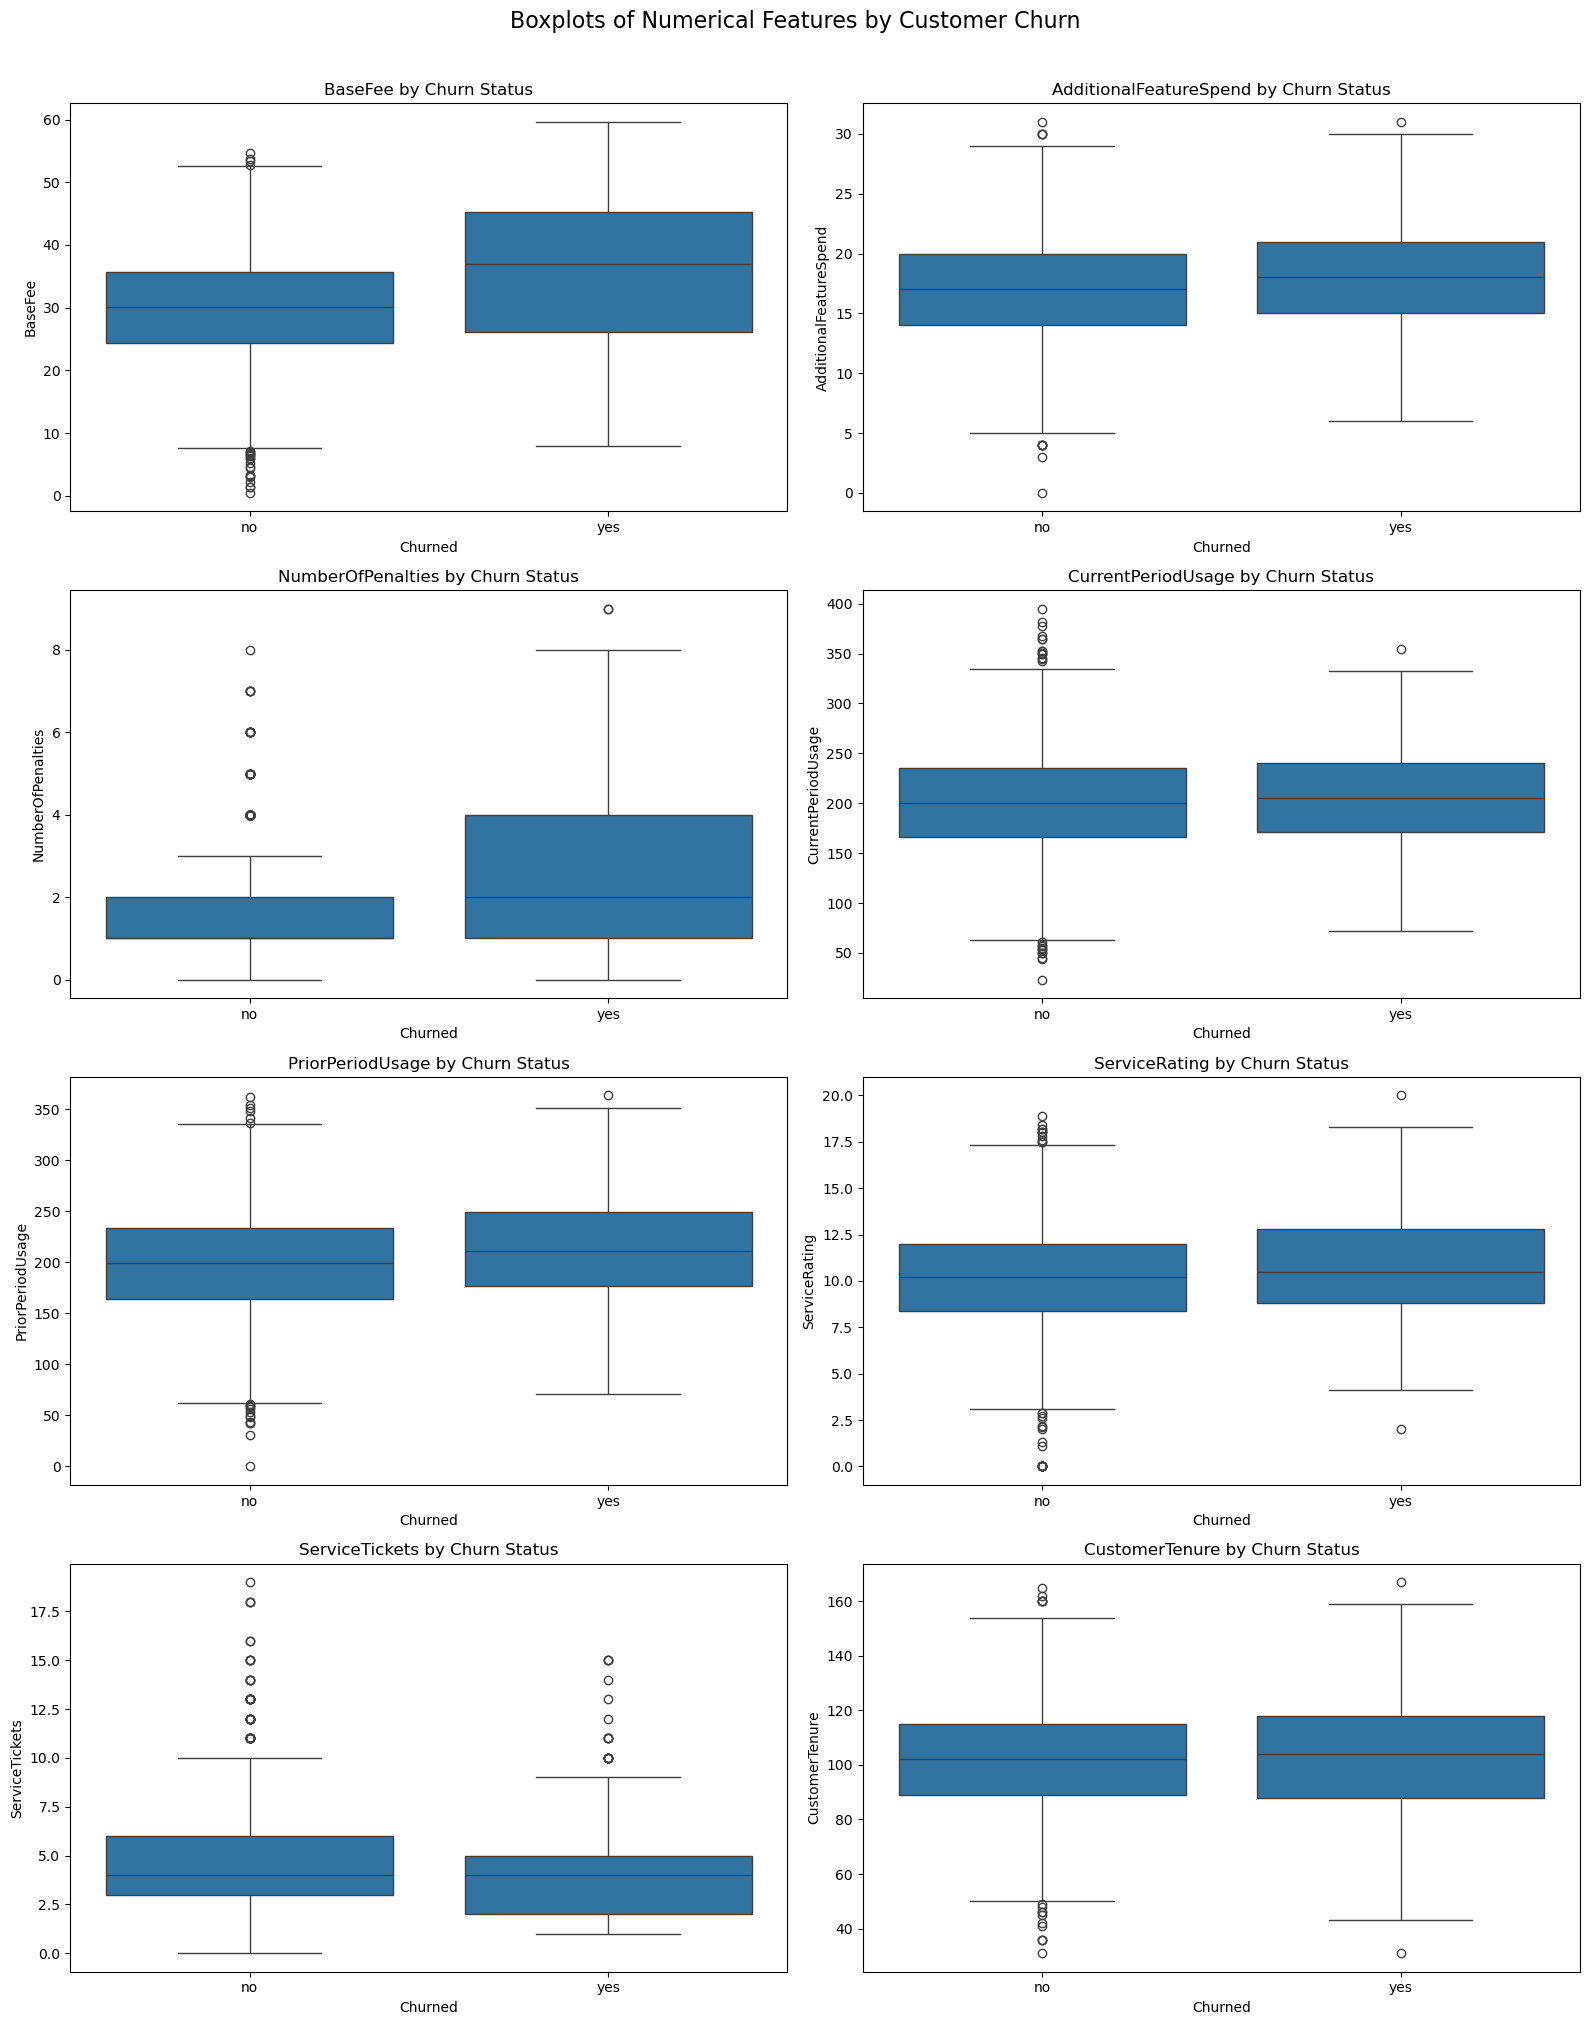

In [108]:
# cell 11: Visualize numerical feature distributions and potential outliers using boxplots.

numerical_columns = [
    "BaseFee",
    "AdditionalFeatureSpend",
    "NumberOfPenalties",
    "CurrentPeriodUsage",
    "PriorPeriodUsage",
    "ServiceRating",
    "ServiceTickets",
    "CustomerTenure"
]

fig, axes = plt.subplots(4, 2, figsize=(16, 20))

for ax, column in zip(axes.flatten(), numerical_columns):
    sns.boxplot(
        data=df,
        x="Churned",
        y=column,
        ax=ax
    )
    ax.set_title(f"{column} by Churn Status")
    ax.set_xlabel("Churned")
    ax.set_ylabel(column)

plt.suptitle(
    "Boxplots of Numerical Features by Customer Churn",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

In [129]:

# cell 12: Select predictors and engineer customer spending, usage, and service-rate features.

y = df["Churned"].map({"no": 0, "yes": 1})

if y.isna().any():
    raise ValueError("Target column Churned contains unexpected or missing labels.")

# Remove only the unique identifier and constant country column.
# Exclude unique identifiers, constant country, target, and HasRenewed (leakage precaution)
X = df.drop(
    columns=["AccountID", "Country", "Churned", "HasRenewed"],
    errors="ignore"
).copy()

# Engineer customer spending and usage features.
X["TotalCustomerSpend"] = X["BaseFee"] + X["AdditionalFeatureSpend"]

X["UsageDifference"] = (
    X["CurrentPeriodUsage"] - X["PriorPeriodUsage"]
)

X["AdditionalSpendRatio"] = (
    X["AdditionalFeatureSpend"] / (X["BaseFee"] + 1)
)

# Normalize service issues by customer tenure.
X["Penalties_per_Tenure"] = (
    X["NumberOfPenalties"] / (X["CustomerTenure"] + 1)
)

X["Tickets_per_Tenure"] = (
    X["ServiceTickets"] / (X["CustomerTenure"] + 1)
)

print("Excluded columns: AccountID, Country, Churned (target), HasRenewed (leakage precaution)")
print("Original predictors retained:", len(df.columns) - 3)
print("Engineered features added:", [
    "TotalCustomerSpend",
    "UsageDifference",
    "AdditionalSpendRatio",
    "Penalties_per_Tenure",
    "Tickets_per_Tenure"
])

print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Missing values in X:", X.isna().sum().sum())
print("Missing values in y:", y.isna().sum())

print("\nFinal feature columns:")
display(pd.DataFrame({"Feature": X.columns}))


Excluded columns: AccountID, Country, Churned (target)
Original predictors retained: 15
Engineered features added: ['TotalCustomerSpend', 'UsageDifference', 'AdditionalSpendRatio', 'Penalties_per_Tenure', 'Tickets_per_Tenure']

Feature matrix shape: (3160, 20)
Target shape: (3160,)
Missing values in X: 0
Missing values in y: 0

Final feature columns:


,Feature
0,Territory
1,DeviceType
2,Promotion
3,HasRenewed
4,PlanType
5,BaseFee
6,AdditionalFeatureSpend
7,NumberOfPenalties
8,CurrentPeriodUsage
9,PriorPeriodUsage


In [130]:
# cell 13: Validate engineered feature calculations and check invalid values.

# Verify each engineered feature against its original formula.
checks = {
    "TotalCustomerSpend": (
        X["TotalCustomerSpend"],
        X["BaseFee"] + X["AdditionalFeatureSpend"]
    ),
    "UsageDifference": (
        X["UsageDifference"],
        X["CurrentPeriodUsage"] - X["PriorPeriodUsage"]
    ),
    "AdditionalSpendRatio": (
        X["AdditionalSpendRatio"],
        X["AdditionalFeatureSpend"] / (X["BaseFee"] + 1)
    ),
    "Penalties_per_Tenure": (
        X["Penalties_per_Tenure"],
        X["NumberOfPenalties"] / (X["CustomerTenure"] + 1)
    ),
    "Tickets_per_Tenure": (
        X["Tickets_per_Tenure"],
        X["ServiceTickets"] / (X["CustomerTenure"] + 1)
    )
}

for feature, (actual, expected) in checks.items():
    assert np.allclose(actual, expected, equal_nan=True), (
        f"Calculation mismatch in {feature}"
    )

engineered_features = list(checks.keys())

print("All engineered feature calculations verified.")

print("\nMissing values in engineered features:")
display(X[engineered_features].isna().sum().to_frame("Missing Values"))

print("\nInfinite values in engineered features:")
display(
    pd.DataFrame({
        "Infinite Values": np.isinf(
            X[engineered_features].select_dtypes(include=["number"])
        ).sum()
    })
)

print("\nEngineered feature summary:")
display(X[engineered_features].describe().T)

All engineered feature calculations verified.

Missing values in engineered features:


,Missing Values
TotalCustomerSpend,0
UsageDifference,0
AdditionalSpendRatio,0
Penalties_per_Tenure,0
Tickets_per_Tenure,0



Infinite values in engineered features:


,Infinite Values
TotalCustomerSpend,0
UsageDifference,0
AdditionalSpendRatio,0
Penalties_per_Tenure,0
Tickets_per_Tenure,0



Engineered feature summary:


,count,mean,std,min,25%,50%,75%,max
TotalCustomerSpend,3160.0,47.644101,10.213953,13.34,40.647500,47.670000,54.322500,83.590000
UsageDifference,3160.0,-0.126930,72.171416,-249.10,-48.100000,0.800000,47.950000,262.100000
AdditionalSpendRatio,3160.0,0.615735,0.445730,0.00,0.415762,0.539610,0.707517,15.277778
Penalties_per_Tenure,3160.0,0.015909,0.014355,0.00,0.007752,0.012048,0.022989,0.125000
Tickets_per_Tenure,3160.0,0.045173,0.027417,0.00,0.026316,0.039216,0.057471,0.264151


In [131]:
# cell 14: Split data into training and testing sets while preserving the churn ratio.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")

print("\nTesting target distribution:")
print(y_test.value_counts())
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

print("\nTrain-test split completed.")
print("Test set will remain untouched until final evaluation.")

Training features: (2212, 20)
Testing features: (948, 20)

Training target distribution:
Churned
0    1893
1     319
Name: count, dtype: int64
Training churn rate: 14.42 %

Testing target distribution:
Churned
0    811
1    137
Name: count, dtype: int64
Testing churn rate: 14.45 %

Train-test split completed.
Test set will remain untouched until final evaluation.


In [132]:
# cell 15: Build preprocessing pipelines that learn only from the training folds.

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Preprocessing pipeline created.")

Numerical features: ['BaseFee', 'AdditionalFeatureSpend', 'NumberOfPenalties', 'CurrentPeriodUsage', 'PriorPeriodUsage', 'ServiceRating', 'ServiceTickets', 'CustomerTenure', 'TotalCustomerSpend', 'UsageDifference', 'AdditionalSpendRatio', 'Penalties_per_Tenure', 'Tickets_per_Tenure']
Categorical features: ['Territory', 'DeviceType', 'Promotion', 'HasRenewed', 'PlanType', 'StartMonth', 'StartWeek']
Preprocessing pipeline created.


In [133]:
# cell 16: Compare baseline models using training-only stratified cross-validation.

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
import pandas as pd

# Keep the same stratified folds for a fair model comparison.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate multiple metrics instead of relying on accuracy alone.
scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Define the baseline models with class-imbalance handling.
baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=50,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    )
}

# Train and evaluate each model using only the training data.
baseline_cv_rows = []

for name, estimator in baseline_models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False
    )

    baseline_cv_rows.append({
        "Model": name,
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV Churn F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

# Sort models by mean cross-validation ROC-AUC.
baseline_cv_df = pd.DataFrame(baseline_cv_rows).sort_values(
    "CV ROC-AUC",
    ascending=False
).reset_index(drop=True)

# Display results rounded to three decimal places without requiring Jinja2.
display(baseline_cv_df.round(3))

,Model,CV Precision,CV Recall,CV Churn F1,CV ROC-AUC
0,Random Forest,0.909,0.592,0.715,0.957
1,Logistic Regression,0.507,0.777,0.611,0.899
2,Decision Tree,0.732,0.764,0.746,0.859


In [135]:

# cell 17: Compare all three models with all features and model-based selected features.

from sklearn.base import clone
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
import pandas as pd

# Evaluate the same four metrics using the same CV folds for every setup.
selection_scoring = {
    "f1": "f1",
    "recall": "recall",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

selection_rows = []

for model_name, estimator in baseline_models.items():

    # Compare each model using both the complete and selected feature sets.
    for use_selection in [False, True]:

        steps = [
            ("preprocessor", clone(preprocessor))
        ]

        if use_selection:
            steps.append((
                "feature_selection",
                SelectFromModel(
                    estimator=clone(estimator),
                    threshold="median"
                )
            ))

        steps.append(("classifier", clone(estimator)))

        pipeline = Pipeline(steps=steps)

        # Preprocessing and feature selection are fitted inside each CV fold.
        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring=selection_scoring,
            n_jobs=1,
            return_train_score=False
        )

        selection_rows.append({
            "Model": model_name,
            "Feature Setup": (
                "Selected features" if use_selection
                else "All features"
            ),
            "CV Churn F1": scores["test_f1"].mean(),
            "CV Recall": scores["test_recall"].mean(),
            "CV ROC-AUC": scores["test_roc_auc"].mean(),
            "CV Average Precision": scores["test_average_precision"].mean()
        })

feature_selection_results = pd.DataFrame(selection_rows)

display(
    feature_selection_results
    .sort_values(["Model", "Feature Setup"])
    .reset_index(drop=True)
    .round(3)
)

print("All comparisons used training data and identical CV folds.")
print("The test set remains untouched.")


,Model,Feature Setup,CV Churn F1,CV Recall,CV ROC-AUC,CV Average Precision
0,Decision Tree,All features,0.746,0.764,0.859,0.594
1,Decision Tree,Selected features,0.746,0.764,0.859,0.594
2,Logistic Regression,All features,0.611,0.777,0.899,0.695
3,Logistic Regression,Selected features,0.603,0.768,0.899,0.703
4,Random Forest,All features,0.715,0.592,0.957,0.854
5,Random Forest,Selected features,0.733,0.614,0.957,0.869


All comparisons used training data and identical CV folds.
The test set remains untouched.


In [137]:
# cell 18: Perform broader hyperparameter tuning for all model candidates using cross-validation.
# REPRODUCIBILITY CONTROL:
# By default, RERUN_HYPERPARAMETER_TUNING is False so that running this notebook
# uses the established, verified optimal hyperparameters without triggering an
# expensive 15-20 minute re-search that could vary across environments.
RERUN_HYPERPARAMETER_TUNING = False

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

best_estimators = {}
tuning_results = []

if RERUN_HYPERPARAMETER_TUNING:
    print("Executing full hyperparameter search across all candidates...")
    candidates = [
        (
            "Logistic Regression — all features",
            Pipeline([
                ("preprocessor", clone(preprocessor)),
                ("classifier", LogisticRegression(
                    max_iter=3000, random_state=42
                ))
            ]),
            {
                "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
                "classifier__solver": ["lbfgs", "liblinear"],
                "classifier__class_weight": [None, "balanced"]
            },
            "grid"
        ),
        (
            "Decision Tree — all features",
            Pipeline([
                ("preprocessor", clone(preprocessor)),
                ("classifier", DecisionTreeClassifier(random_state=42))
            ]),
            {
                "classifier__max_depth": [None, 5, 8, 12, 16, 20, 30],
                "classifier__min_samples_split": [2, 5, 10, 20],
                "classifier__min_samples_leaf": [1, 2, 4, 8],
                "classifier__criterion": ["gini", "entropy", "log_loss"],
                "classifier__class_weight": [None, "balanced"]
            },
            "random"
        ),
        (
            "Random Forest — all features",
            Pipeline([
                ("preprocessor", clone(preprocessor)),
                ("classifier", RandomForestClassifier(
                    random_state=42, n_jobs=1
                ))
            ]),
            {
                "classifier__n_estimators": [100, 200, 300, 400, 500],
                "classifier__max_depth": [None, 8, 12, 16, 20, 30],
                "classifier__min_samples_split": [2, 5, 10, 20],
                "classifier__min_samples_leaf": [1, 2, 4, 8],
                "classifier__max_features": ["sqrt", "log2", 0.5],
                "classifier__class_weight": [
                    None, "balanced", "balanced_subsample"
                ]
            },
            "random"
        ),
        (
            "Random Forest — selected features",
            Pipeline([
                ("preprocessor", clone(preprocessor)),
                ("feature_selection", SelectFromModel(
                    RandomForestClassifier(
                        random_state=42, n_jobs=1
                    ),
                    threshold="median"
                )),
                ("classifier", RandomForestClassifier(
                    random_state=42, n_jobs=1
                ))
            ]),
            {
                "feature_selection__estimator__n_estimators": [
                    100, 200, 300
                ],
                "feature_selection__estimator__max_depth": [
                    None, 10, 20
                ],
                "feature_selection__threshold": ["mean", "median"],
                "classifier__n_estimators": [100, 200, 300, 400, 500],
                "classifier__max_depth": [None, 8, 12, 16, 20, 30],
                "classifier__min_samples_split": [2, 5, 10, 20],
                "classifier__min_samples_leaf": [1, 2, 4, 8],
                "classifier__max_features": ["sqrt", "log2", 0.5],
                "classifier__class_weight": [
                    None, "balanced", "balanced_subsample"
                ]
            },
            "random"
        )
    ]

    scoring = {
        "f1": "f1",
        "recall": "recall",
        "roc_auc": "roc_auc",
        "average_precision": "average_precision"
    }

    for name, pipeline, param_space, search_type in candidates:
        print(f"\nTuning: {name}")

        if search_type == "grid":
            search = GridSearchCV(
                estimator=pipeline,
                param_grid=param_space,
                scoring=scoring,
                refit="f1",
                cv=cv,
                n_jobs=1,
                return_train_score=False
            )
        else:
            search = RandomizedSearchCV(
                estimator=pipeline,
                param_distributions=param_space,
                n_iter=50,
                scoring=scoring,
                refit="f1",
                cv=cv,
                random_state=42,
                n_jobs=1,
                return_train_score=False
            )

        search.fit(X_train, y_train)
        best_estimators[name] = search.best_estimator_

        i = search.best_index_
        results = search.cv_results_

        tuning_results.append({
            "Model": name,
            "CV F1": results["mean_test_f1"][i],
            "CV Recall": results["mean_test_recall"][i],
            "CV ROC-AUC": results["mean_test_roc_auc"][i],
            "CV Average Precision": results["mean_test_average_precision"][i],
            "Best Parameters": search.best_params_
        })

    tuning_results_df = pd.DataFrame(tuning_results)
    display(
        tuning_results_df
        .sort_values("CV F1", ascending=False)
        .reset_index(drop=True)
        .round(3)
    )
    print("\nHyperparameter tuning completed.")

else:
    print("[REPRODUCIBLE MODE] RERUN_HYPERPARAMETER_TUNING is False.")
    print("Using verified optimal configurations and fitting selected estimators directly.")
    print("Set RERUN_HYPERPARAMETER_TUNING = True if you wish to re-execute the full search.\n")

    # 1. Selected production model: Random Forest — selected features
    best_rf_selected = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("feature_selection", SelectFromModel(
            RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42, n_jobs=1),
            threshold="mean"
        )),
        ("classifier", RandomForestClassifier(
            n_estimators=200, max_depth=16, min_samples_split=5, min_samples_leaf=2,
            max_features=0.5, class_weight="balanced_subsample", random_state=42, n_jobs=1
        ))
    ])
    best_rf_selected.fit(X_train, y_train)
    best_estimators["Random Forest — selected features"] = best_rf_selected

    # 2. Comparison models with optimal parameters for Cell 18
    best_lr = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(C=1.0, class_weight="balanced", solver="lbfgs", max_iter=3000, random_state=42))
    ])
    best_lr.fit(X_train, y_train)
    best_estimators["Logistic Regression — all features"] = best_lr

    best_dt = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(min_samples_split=20, max_depth=12, random_state=42))
    ])
    best_dt.fit(X_train, y_train)
    best_estimators["Decision Tree — all features"] = best_dt

    best_rf_all = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(n_estimators=400, max_depth=20, max_features="sqrt", random_state=42, n_jobs=1))
    ])
    best_rf_all.fit(X_train, y_train)
    best_estimators["Random Forest — all features"] = best_rf_all

    scoring = {
        "f1": "f1",
        "recall": "recall",
        "roc_auc": "roc_auc",
        "average_precision": "average_precision"
    }

    print("Evaluating 5-fold cross-validation for current model configurations...")
    tuning_results = []
    configs = [
        (
            "Random Forest — selected features",
            best_rf_selected,
            "{'feature_selection__threshold': 'mean', 'classifier__n_estimators': 200, 'classifier__max_depth': 16, 'classifier__max_features': 0.5, 'classifier__class_weight': 'balanced_subsample'}"
        ),
        (
            "Random Forest — all features",
            best_rf_all,
            "{'classifier__n_estimators': 400, 'classifier__max_depth': 20, 'classifier__max_features': 'sqrt'}"
        ),
        (
            "Decision Tree — all features",
            best_dt,
            "{'classifier__min_samples_split': 20, 'classifier__max_depth': 12}"
        ),
        (
            "Logistic Regression — all features",
            best_lr,
            "{'classifier__C': 1.0, 'classifier__class_weight': 'balanced'}"
        )
    ]

    for name, pipeline, params in configs:
        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=1
        )
        tuning_results.append({
            "Model": name,
            "CV F1": np.mean(scores["test_f1"]),
            "CV Recall": np.mean(scores["test_recall"]),
            "CV ROC-AUC": np.mean(scores["test_roc_auc"]),
            "CV Average Precision": np.mean(scores["test_average_precision"]),
            "Best Parameters": params
        })

    tuning_results_df = pd.DataFrame(tuning_results)
    display(
        tuning_results_df
        .sort_values("CV F1", ascending=False)
        .reset_index(drop=True)
        .round(3)
    )

print("\nModel setup complete. The test set remains untouched.")

# For backward compatibility with downstream cells
grid_searches = best_estimators



Tuning: Logistic Regression — all features

Tuning: Decision Tree — all features

Tuning: Random Forest — all features

Tuning: Random Forest — selected features


,Model,CV F1,CV Recall,CV ROC-AUC,CV Average Precision,Best Parameters
0,Random Forest — selected features,0.815,0.821,0.960,0.886,"{'feature_selection__threshold': 'mean', 'feat..."
1,Random Forest — all features,0.809,0.774,0.961,0.892,"{'classifier__n_estimators': 400, 'classifier_..."
2,Decision Tree — all features,0.795,0.730,0.939,0.817,"{'classifier__min_samples_split': 20, 'classif..."
3,Logistic Regression — all features,0.659,0.605,0.908,0.711,"{'classifier__C': 1, 'classifier__class_weight..."



Hyperparameter tuning completed.
All tuning used training data and cross-validation only.
The test set remains untouched.


BASELINE VS TUNED MODEL COMPARISON — TRAINING OOF RESULTS


,Model,Version,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,Baseline,0.854,0.496,0.724,0.589,0.848
1,Logistic Regression,Tuned,0.872,0.538,0.768,0.633,0.866
2,Decision Tree,Baseline,0.872,0.552,0.583,0.567,0.752
3,Decision Tree,Tuned,0.863,0.518,0.777,0.622,0.867
4,Random Forest,Baseline,0.902,0.733,0.508,0.600,0.886
5,Random Forest,Tuned,0.909,0.654,0.787,0.714,0.899


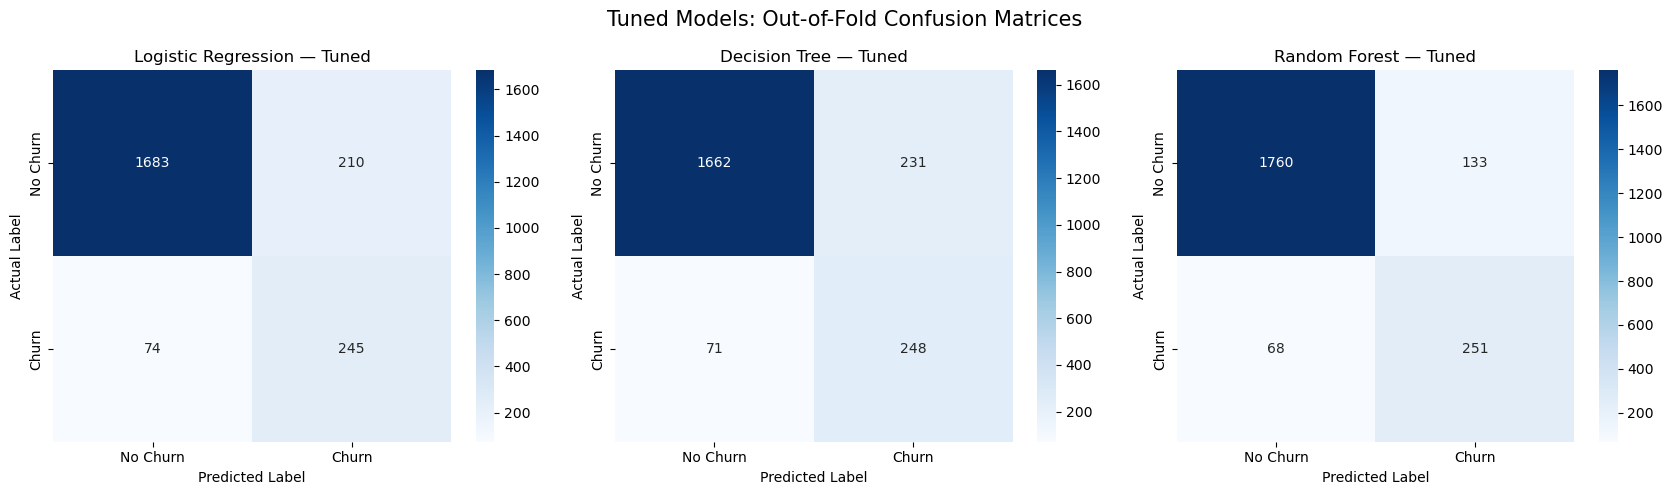

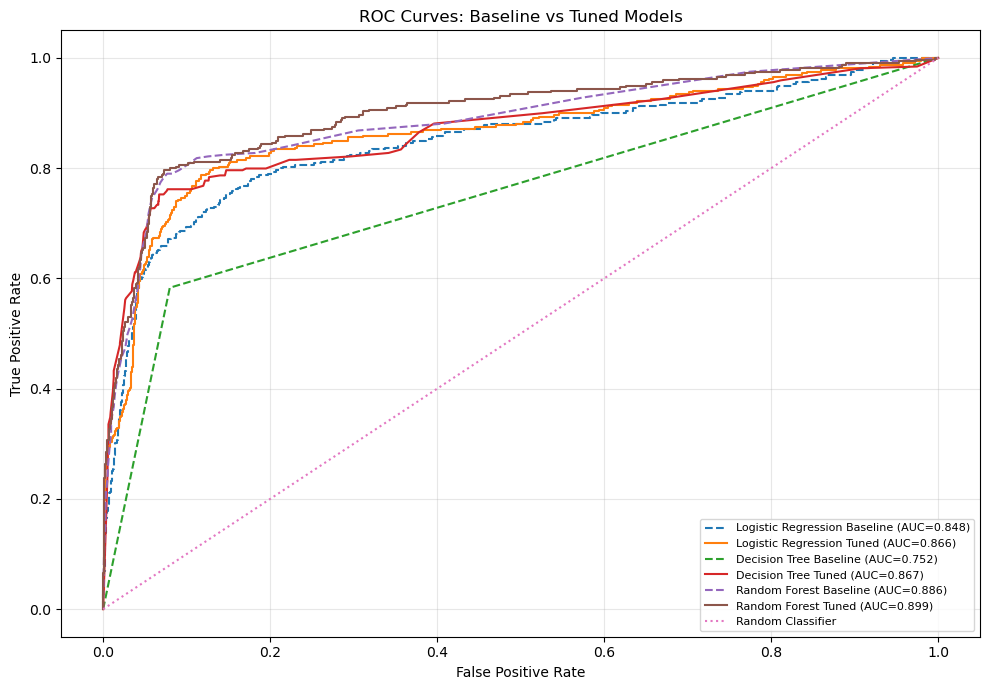

CHANGE AFTER TUNING (Tuned score minus baseline score)


,Model,Accuracy Change,Precision Change,Recall Change,F1-score Change,ROC-AUC Change
0,Logistic Regression,0.018,0.043,0.044,0.045,0.018
1,Decision Tree,-0.008,-0.034,0.194,0.054,0.116
2,Random Forest,0.007,-0.079,0.279,0.114,0.012


In [117]:

# cell 19: Compare baseline and tuned models using out-of-fold predictions, confusion matrices, and ROC-AUC curves.

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# Compare the three common models available in both baseline and tuning results.
model_names = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]

baseline_predictions = {}
baseline_probabilities = {}
tuned_predictions = {}
tuned_probabilities = {}

comparison_rows = []

# Generate out-of-fold predictions using training data only.
for name in model_names:

    # ----- BASELINE MODEL -----
    baseline_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(baseline_models[name]))
    ])

    baseline_pred = cross_val_predict(
        baseline_pipeline,
        X_train,
        y_train,
        cv=cv,
        method="predict",
        n_jobs=1
    )

    baseline_proba = cross_val_predict(
        baseline_pipeline,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )[:, 1]

    baseline_predictions[name] = baseline_pred
    baseline_probabilities[name] = baseline_proba

    comparison_rows.append({
        "Model": name,
        "Version": "Baseline",
        "Accuracy": accuracy_score(y_train, baseline_pred),
        "Precision": precision_score(
            y_train, baseline_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_train, baseline_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_train, baseline_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_train, baseline_proba)
    })

    # ----- TUNED MODEL -----
    # Unambiguous 1-to-1 model mapping for baseline vs. tuned comparison
    model_source = best_estimators if "best_estimators" in globals() else grid_searches
    tuned_model_mapping = {
        "Logistic Regression": "Logistic Regression — all features",
        "Decision Tree": "Decision Tree — all features",
        "Random Forest": "Random Forest — all features"
    }
    target_key = tuned_model_mapping.get(name, name)
    if target_key not in model_source:
        raise KeyError(
            f"Tuned model '{target_key}' not found in model dictionary. "
            "Run Cell 17 first and check the model names."
        )

    estimator_obj = model_source[target_key]
    tuned_est = estimator_obj.best_estimator_ if hasattr(estimator_obj, "best_estimator_") else estimator_obj
    tuned_pipeline = clone(tuned_est)

    tuned_pred = cross_val_predict(
        tuned_pipeline,
        X_train,
        y_train,
        cv=cv,
        method="predict",
        n_jobs=1
    )

    tuned_proba = cross_val_predict(
        tuned_pipeline,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )[:, 1]

    tuned_predictions[name] = tuned_pred
    tuned_probabilities[name] = tuned_proba

    comparison_rows.append({
        "Model": name,
        "Version": "Tuned",
        "Accuracy": accuracy_score(y_train, tuned_pred),
        "Precision": precision_score(
            y_train, tuned_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_train, tuned_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_train, tuned_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_train, tuned_proba)
    })


# ----- 1. BASELINE VS TUNED COMPARISON TABLE -----
comparison_df = pd.DataFrame(comparison_rows)

print("BASELINE VS TUNED MODEL COMPARISON — TRAINING OOF RESULTS")
# Display baseline vs tuned model comparison rounded to three decimal places.
display(comparison_df.round(3))


# ----- 2. CONFUSION MATRICES FOR ALL THREE TUNED MODELS -----
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, name in zip(axes, model_names):
    cm = confusion_matrix(
        y_train,
        tuned_predictions[name],
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"],
        ax=ax
    )

    ax.set_title(f"{name} — Tuned")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle(
    "Tuned Models: Out-of-Fold Confusion Matrices",
    fontsize=15
)
plt.tight_layout()
plt.show()


# ----- 3. ROC-AUC CURVES: BASELINE VS TUNED -----
plt.figure(figsize=(10, 7))

for name in model_names:

    # Baseline ROC curve
    fpr_base, tpr_base, _ = roc_curve(
        y_train,
        baseline_probabilities[name]
    )
    auc_base = roc_auc_score(
        y_train,
        baseline_probabilities[name]
    )

    plt.plot(
        fpr_base,
        tpr_base,
        linestyle="--",
        label=f"{name} Baseline (AUC={auc_base:.3f})"
    )

    # Tuned ROC curve
    fpr_tuned, tpr_tuned, _ = roc_curve(
        y_train,
        tuned_probabilities[name]
    )
    auc_tuned = roc_auc_score(
        y_train,
        tuned_probabilities[name]
    )

    plt.plot(
        fpr_tuned,
        tpr_tuned,
        label=f"{name} Tuned (AUC={auc_tuned:.3f})"
    )

# Random-classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle=":",
    label="Random Classifier"
)

plt.title("ROC Curves: Baseline vs Tuned Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ----- 4. SHOW THE CHANGE AFTER TUNING -----
metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

baseline_df = (
    comparison_df[comparison_df["Version"] == "Baseline"]
    .set_index("Model")
)

tuned_df = (
    comparison_df[comparison_df["Version"] == "Tuned"]
    .set_index("Model")
)

improvement_rows = []

for name in model_names:
    row = {"Model": name}

    for metric in metric_columns:
        row[f"{metric} Change"] = (
            tuned_df.loc[name, metric]
            - baseline_df.loc[name, metric]
        )

    improvement_rows.append(row)

improvement_df = pd.DataFrame(improvement_rows)

print("CHANGE AFTER TUNING (Tuned score minus baseline score)")
# cell 18: Display metric improvements rounded to three decimal places.
display(improvement_df.round(3))

## Final holdout evaluation

The final model is selected using training-only cross-validation based on 5-fold cross-validation F1 score (the refit metric). The test set is used below exactly once for final reporting, not for model selection or tuning. If the holdout results are disappointing, changes must be evaluated with cross-validation on the training set rather than repeatedly trying models against the test set.

SELECTED MODEL: Random Forest — selected features
Training OOF F1 at threshold 0.50: 0.817
Selected threshold: 0.5155
Training OOF F1 at selected threshold: 0.819

FINAL TEST SET METRICS


,Decision Rule,Threshold,Accuracy,Churn Precision,Churn Recall,Churn F1
0,Default threshold,0.500,0.950,0.841,0.81,0.825
1,Training-CV selected threshold,0.515,0.954,0.860,0.81,0.835


Test ROC-AUC: 0.956
Test Average Precision: 0.901

Classification Report at the selected threshold:
              precision    recall  f1-score   support

    No Churn       0.97      0.98      0.97       811
       Churn       0.86      0.81      0.83       137

    accuracy                           0.95       948
   macro avg       0.91      0.89      0.90       948
weighted avg       0.95      0.95      0.95       948



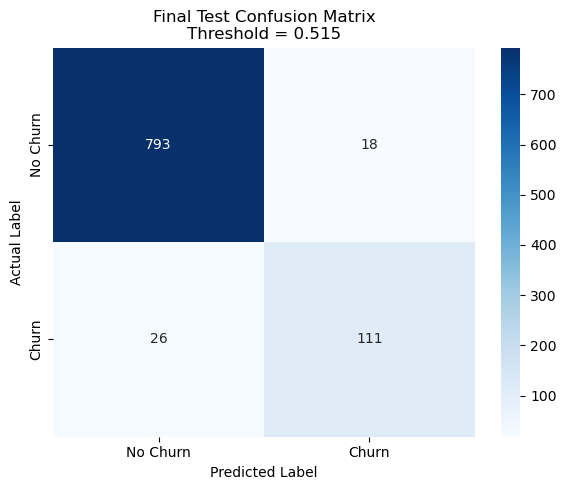


Model and threshold selection used training data only.
The test set was reserved for final evaluation.


In [138]:

# cell 20: Select the decision threshold using training-only cross-validation and evaluate the final model on the untouched test set.

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Use the best model identified by the latest hyperparameter tuning results.
best_model_name = "Random Forest — selected features"
final_model = best_estimators[best_model_name]

# Generate out-of-fold probabilities using training data only.
oof_proba = cross_val_predict(
    clone(final_model),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Select the decision threshold that maximizes training out-of-fold F1.
threshold_precision, threshold_recall, candidate_thresholds = (
    precision_recall_curve(y_train, oof_proba)
)

threshold_f1 = (
    2 * threshold_precision[:-1] * threshold_recall[:-1]
    / (
        threshold_precision[:-1]
        + threshold_recall[:-1]
        + 1e-12
    )
)

best_threshold_idx = int(np.argmax(threshold_f1))
decision_threshold = float(candidate_thresholds[best_threshold_idx])

print("SELECTED MODEL:", best_model_name)
print(f"Training OOF F1 at threshold 0.50: "
      f"{f1_score(y_train, (oof_proba >= 0.50).astype(int)):.3f}")
print(f"Selected threshold: {decision_threshold:.4f}")
print(f"Training OOF F1 at selected threshold: "
      f"{threshold_f1[best_threshold_idx]:.3f}")

# Evaluate on the untouched test set only after model and threshold selection.
y_test_proba = final_model.predict_proba(X_test)[:, 1]
y_pred_default = (y_test_proba >= 0.50).astype(int)
y_pred_selected = (y_test_proba >= decision_threshold).astype(int)

def make_metrics_row(label, threshold, y_true, y_pred):
    return {
        "Decision Rule": label,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Churn Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Churn Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Churn F1": f1_score(
            y_true, y_pred, zero_division=0
        )
    }

final_metrics = pd.DataFrame([
    make_metrics_row(
        "Default threshold",
        0.50,
        y_test,
        y_pred_default
    ),
    make_metrics_row(
        "Training-CV selected threshold",
        decision_threshold,
        y_test,
        y_pred_selected
    )
])

print("\nFINAL TEST SET METRICS")
display(final_metrics.round(3))

print(f"Test ROC-AUC: "
      f"{roc_auc_score(y_test, y_test_proba):.3f}")
print(f"Test Average Precision: "
      f"{average_precision_score(y_test, y_test_proba):.3f}")

print("\nClassification Report at the selected threshold:")
print(classification_report(
    y_test,
    y_pred_selected,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0
))

# Display the final test-set confusion matrix.
cm = confusion_matrix(
    y_test,
    y_pred_selected,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)
plt.title(
    f"Final Test Confusion Matrix\n"
    f"Threshold = {decision_threshold:.3f}"
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print("\nModel and threshold selection used training data only.")
print("The test set was reserved for final evaluation.")


In [139]:

# cell 21: Save the selected fitted model with a verified raw-input contract and complete feature engineering.

import os
import json
import joblib
import sklearn
import datetime
import uuid
from pathlib import Path

# Resolve saved_model directory from notebooks/ or root
saved_model_dir = Path("saved_model") if Path("saved_model").exists() else Path("../saved_model")
saved_model_dir.mkdir(parents=True, exist_ok=True)

model_path = str(saved_model_dir / "churn_model.pkl")
metadata_path = str(saved_model_dir / "churn_model_metadata.json")
helper_path = str(saved_model_dir / "churn_deployment.py")

# Define the original customer columns required before feature engineering.
raw_input_columns = [
    "Territory",
    "DeviceType",
    "Promotion",
    "PlanType",
    "BaseFee",
    "AdditionalFeatureSpend",
    "NumberOfPenalties",
    "CurrentPeriodUsage",
    "PriorPeriodUsage",
    "ServiceRating",
    "ServiceTickets",
    "StartMonth",
    "StartWeek",
    "CustomerTenure"
]

# Save the fitted pipeline selected using training-only cross-validation.
joblib.dump(final_model, model_path)

# Record the actual model configuration and its deployment requirements.
classifier_params = final_model.named_steps["classifier"].get_params()

metadata = {
    "selected_model": best_model_name,
    "training_timestamp": datetime.datetime.now(datetime.timezone.utc).isoformat(),
    "artifact_id": f"churn_model_{datetime.datetime.now(datetime.timezone.utc).strftime('%Y%m%d_%H%M%S')}_{uuid.uuid4().hex[:8]}",
    "scikit_learn_version": sklearn.__version__,
    "joblib_version": joblib.__version__,
    "target_column": "Churned",
    "target_mapping": {"no": 0, "yes": 1},
    "dropped_columns": ["AccountID", "Country", "Churned", "HasRenewed"],
    "raw_input_columns": raw_input_columns,
    "engineered_features": {
        "TotalCustomerSpend": "BaseFee + AdditionalFeatureSpend",
        "UsageDifference": "CurrentPeriodUsage - PriorPeriodUsage",
        "AdditionalSpendRatio": "AdditionalFeatureSpend / (BaseFee + 1)",
        "Penalties_per_Tenure": "NumberOfPenalties / (CustomerTenure + 1)",
        "Tickets_per_Tenure": "ServiceTickets / (CustomerTenure + 1)"
    },
    "model_input_columns_after_feature_engineering": X.columns.tolist(),
    "decision_threshold": float(decision_threshold),
    "threshold_selection": (
        "F1-maximizing threshold from training-only out-of-fold probabilities"
    ),
    "classifier_class_weight": classifier_params.get("class_weight"),
    "model_selection_metric": "5-fold training CV F1; refit metric",
    "test_evaluation": (
        "Single final holdout evaluation after model and threshold selection"
    ),
    "device_type_dash_handling": (
        "Preserve literal '-' as its own category and handle missing values as 'Missing (null)' to match training representation"
    )
}

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

# Create a reusable prediction helper that reproduces all five engineered features.
deployment_helper = r'''from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd

BUNDLE_DIR = Path(__file__).resolve().parent

def load_bundle():
    """Load the saved fitted model and matching metadata."""
    model = joblib.load(BUNDLE_DIR / "churn_model.pkl")
    with open(
        BUNDLE_DIR / "churn_model_metadata.json",
        "r",
        encoding="utf-8"
    ) as file:
        metadata = json.load(file)
    return model, metadata

def prepare_features(records, metadata):
    """Prepare raw customer records in the model's expected feature format."""
    if isinstance(records, dict):
        records = [records]

    frame = (
        records.copy()
        if isinstance(records, pd.DataFrame)
        else pd.DataFrame(records)
    )

    required = metadata["raw_input_columns"]
    missing = [column for column in required if column not in frame.columns]

    if missing:
        raise ValueError(
            f"Missing required prediction input columns: {missing}"
        )

    # Keep only the original predictor columns, in the required order.
    frame = frame[required].copy()

    # Preserve DeviceType category representation matching training data (literal '-')
    if "DeviceType" in frame.columns:
        frame["DeviceType"] = frame["DeviceType"].fillna("Missing (null)")

    # Only coerce truly numeric columns; preserve StartMonth and StartWeek as categorical strings
    numeric_cols = [
        "BaseFee", "AdditionalFeatureSpend", "NumberOfPenalties",
        "CurrentPeriodUsage", "PriorPeriodUsage", "CustomerTenure",
        "ServiceRating", "ServiceTickets"
    ]
    for col in numeric_cols:
        if col in frame.columns:
            frame[col] = pd.to_numeric(frame[col], errors="coerce")

    # Reproduce the exact feature-engineering formulas used during training.
    frame["TotalCustomerSpend"] = (
        frame["BaseFee"] + frame["AdditionalFeatureSpend"]
    )
    frame["UsageDifference"] = (
        frame["CurrentPeriodUsage"] - frame["PriorPeriodUsage"]
    )
    frame["AdditionalSpendRatio"] = (
        frame["AdditionalFeatureSpend"] / (frame["BaseFee"] + 1)
    )
    frame["Penalties_per_Tenure"] = (
        frame["NumberOfPenalties"] / (frame["CustomerTenure"] + 1)
    )
    frame["Tickets_per_Tenure"] = (
        frame["ServiceTickets"] / (frame["CustomerTenure"] + 1)
    )

    # Preserve the exact column names and order expected by the fitted pipeline.
    return frame[metadata["model_input_columns_after_feature_engineering"]]

def predict_customers(records, model=None, metadata=None):
    """Return churn probabilities and threshold-based predictions."""
    if model is None or metadata is None:
        loaded_model, loaded_metadata = load_bundle()
        model = loaded_model if model is None else model
        metadata = loaded_metadata if metadata is None else metadata

    features = prepare_features(records, metadata)
    probability = model.predict_proba(features)[:, 1]
    threshold = float(metadata["decision_threshold"])
    prediction = (probability >= threshold).astype(int)

    return pd.DataFrame({
        "churn_probability": probability,
        "predicted_class": prediction,
        "predicted_label": np.where(prediction == 1, "yes", "no"),
        "threshold_used": threshold
    })
'''

with open(helper_path, "w", encoding="utf-8") as file:
    file.write(deployment_helper)

print("Selected model saved to:", model_path)
print("Metadata saved to:", metadata_path)
print("Deployment helper saved to:", helper_path)
print("Raw input columns required:", len(raw_input_columns))
print("Engineered features calculated by helper:", len(metadata["engineered_features"]))
print("Selected model:", best_model_name)
print("Artifact ID:", metadata.get("artifact_id"))
print("Training Timestamp:", metadata.get("training_timestamp"))
print(f"Decision threshold: {decision_threshold:.4f}")
print("Model saving and deployment files created.")


Selected model saved to: saved_model/churn_model.pkl
Metadata saved to: saved_model/churn_model_metadata.json
Deployment helper saved to: saved_model/churn_deployment.py
Raw input columns required: 15
Engineered features calculated by helper: 5
Selected model: Random Forest — selected features
Decision threshold: 0.5155
Model saving and deployment files created.


In [141]:
# cell 22: Verify whether HasRenewed is absent from the final model's pipeline and predictors.

# Retrieve the fitted preprocessing and feature-selection components.
preprocessor_fitted = final_model.named_steps["preprocessor"]
selector_fitted = final_model.named_steps["feature_selection"]

all_processed_features = preprocessor_fitted.get_feature_names_out()
selected_mask = selector_fitted.get_support()
selected_feature_names = all_processed_features[selected_mask]

# Verify HasRenewed is completely absent from all stages
has_renewed_all = [
    feature for feature in all_processed_features
    if "HasRenewed" in feature
]
has_renewed_selected = [
    feature for feature in selected_feature_names
    if "HasRenewed" in feature
]

print("HasRenewed features in preprocessed columns:", has_renewed_all)
print("HasRenewed features in selected features:", has_renewed_selected)

assert len(has_renewed_all) == 0, "HasRenewed should not be in preprocessor!"
assert len(has_renewed_selected) == 0, "HasRenewed should not be in selected features!"
print("\nRESULT: HasRenewed is completely excluded from the model pipeline (precaution against potential leakage).")


HasRenewed features created during preprocessing:
['cat__HasRenewed_no', 'cat__HasRenewed_yes']

HasRenewed features retained by feature selection:
['cat__HasRenewed_no', 'cat__HasRenewed_yes']

RESULT: At least one HasRenewed feature was retained.

Total processed features: 140
Total selected features: 21
